# Fit five kinetic models and compare bank projection

Level: 2. Prerequisites: Level 1: Read a flotation bank as a kinetic response. Reading time: 30 minutes.

## Objectives

Run OreFlow's bounded nonlinear fits, inspect parameter bounds and residuals, and compare each fitted bank prediction with the engine's exact rate-distributed reference.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; nominal Cu-Mo scenario and generated kinetic record in `data/derived/cases/copper_molybdenum.json`, MIT project licence. The response is simulated, not measured plant data. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The virtual batch data are a mixture of first-order particle-class responses. OreFlow fits first-order, Kelsall, Klimpel, gamma and stretched-exponential forms with bounded Levenberg–Marquardt. It then projects each model through a bank; `kinetic_record` is the production entry point. Fit quality and bank projection are distinct checks.

Llama al ajustador de producción en un caso resuelto. Esto ejecuta las cinco implementaciones de modelos OreFlow.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.kinetics import kinetic_record

# Solve once and use the pipeline's kinetic fitting routine.
case = next(item for item in CASES if item.id == 'copper_molybdenum')
result = simulate(case.ore, case.plant, case.nominal)
fits = kinetic_record(result.flotation, result.ore, case.nominal.rougher_cells, result.metrics['rougher_recovery_pct'])
print('status:', fits['status'], '| fitted models:', len(fits.get('models', [])))

status: computed | fitted models: 5


Compara RMSE, convergencia y estado de límites; un parámetro en su límite no se interpreta como un óptimo interior.

In [3]:
# Compara RMSE, convergencia y estado de límites; un parámetro en su límite no se interpreta como un óptimo interior.
summary = pd.DataFrame([{'model': m['id'], 'RMSE (points)': m['rmse_pct'],
                          'converged': m['converged'], 'at bound': ', '.join(m['at_bound']) or 'no'}
                         for m in fits['models']])
display(summary.set_index('model').round(4))

,RMSE (points),converged,at bound
model,,,
first_order,1.6397,True,no
kelsall,0.0283,True,no
klimpel,0.3976,True,no
gamma,0.1464,True,no
stretched_exponential,0.6667,True,no


Superpone las curvas ajustadas a las observaciones batch virtuales en los mismos tiempos.

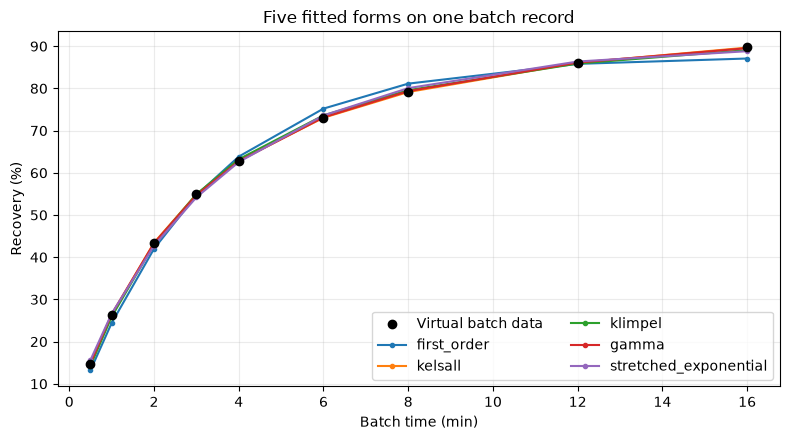

In [4]:
# Superpone las curvas ajustadas a las observaciones batch virtuales en los mismos tiempos.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(fits['times_min'], fits['batch_recovery_pct'], color='black', zorder=4, label='Virtual batch data')
for model in fits['models']:
    ax.plot(fits['times_min'], model['fitted_pct'], marker='.', label=model['id'])
ax.set(xlabel='Batch time (min)', ylabel='Recovery (%)', title='Five fitted forms on one batch record')
ax.grid(True, alpha=.25); ax.legend(ncol=2); fig.tight_layout()

Compara las proyecciones agregadas con el banco exacto de tasas distribuidas e inspecciona la brecha última más allá del último tiempo batch.

In [5]:
# Compara las proyecciones agregadas con el banco exacto de tasas distribuidas e inspecciona la brecha última más allá del último tiempo batch.
projection = pd.DataFrame([{'model': m['id'], 'bank projection (%)': m['bank_projection_pct'],
                              'error vs exact (points)': m['lumping_error_pct'],
                              'ultimate gap (points)': m['ultimate_gap_pct']} for m in fits['models']])
display(projection.round(3))
print('exact bank recovery (%):', fits['bank']['exact_true_flotation_pct'])

,model,bank projection (%),error vs exact (points),ultimate gap (points)
0,first_order,87.393,-6.590,0.471
1,kelsall,92.662,-1.320,4.540
2,klimpel,92.665,-1.318,9.604
3,gamma,92.951,-1.032,7.034
4,stretched_exponential,90.005,-3.977,1.724


exact bank recovery (%): 93.9822410776771


## Results

The curves show approximation quality on the virtual batch record. Bank error compares lumped predictions with the engine's exact distribution reference. A low batch RMSE does not guarantee a low bank-projection error; neither is field validation.

## Summary

You executed the product's fitter and separated fit residual, projection error and extrapolation gap. The whole comparison remains within an engine-generated virtual test.

## References

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3